# BM25F — Retrieval depth grid search
Comparison of 8 retrieval depths and 2 aggregation methods using incomplete known-positive relevance judgments. Run this notebook from `testing/`, alongside `bm25_depth_results/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("bm25_depth_results")
if not DATA_DIR.exists():
    DATA_DIR = Path(".")  # if CSV files are next to this notebook
OUT = DATA_DIR / "plots"
OUT.mkdir(exist_ok=True)

summary = pd.read_csv(DATA_DIR / "summary.csv")
metrics = pd.read_csv(DATA_DIR / "metrics.csv")
coverage = pd.read_csv(DATA_DIR / "expert_coverage.csv")

metric_labels = {"known_recall_at_k":"Known-positive Recall@10", "known_mrr_at_k":"Known-positive MRR@10", "known_ndcg_at_k":"Known-positive nDCG@10"}
methods = sorted(summary.method.unique())
depths = sorted(summary.depth.unique())
print(f"{metrics.query_id.nunique()} queries; depths: {depths}; methods: {methods}")
display(summary.query("query_type == 'overall'").sort_values(['method','depth']))

452 queries; depths: [np.int64(10), np.int64(25), np.int64(50), np.int64(75), np.int64(100), np.int64(150), np.int64(250), np.int64(500)]; methods: ['combsum', 'discounted']


,method,depth,query_type,queries,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k,retrieved_document_count,candidate_researcher_count
1,combsum,10,overall,452,0.326844,0.224479,0.240363,10.0,7.013274
4,combsum,25,overall,452,0.415339,0.229139,0.263945,25.0,14.712389
7,combsum,50,overall,452,0.431232,0.238696,0.274396,50.0,26.241150
10,combsum,75,overall,452,0.411320,0.237888,0.269698,75.0,35.150442
13,combsum,100,overall,452,0.419653,0.231816,0.267619,100.0,43.595133
16,combsum,150,overall,452,0.388385,0.221099,0.251358,150.0,59.309735
19,combsum,250,overall,452,0.359366,0.220823,0.243335,250.0,85.734513
22,combsum,500,overall,452,0.350885,0.213696,0.237080,500.0,134.103982
25,discounted,10,overall,452,0.326844,0.234250,0.246144,10.0,7.013274
28,discounted,25,overall,452,0.415339,0.262316,0.287864,25.0,14.712389


## 1. Overall metric trends

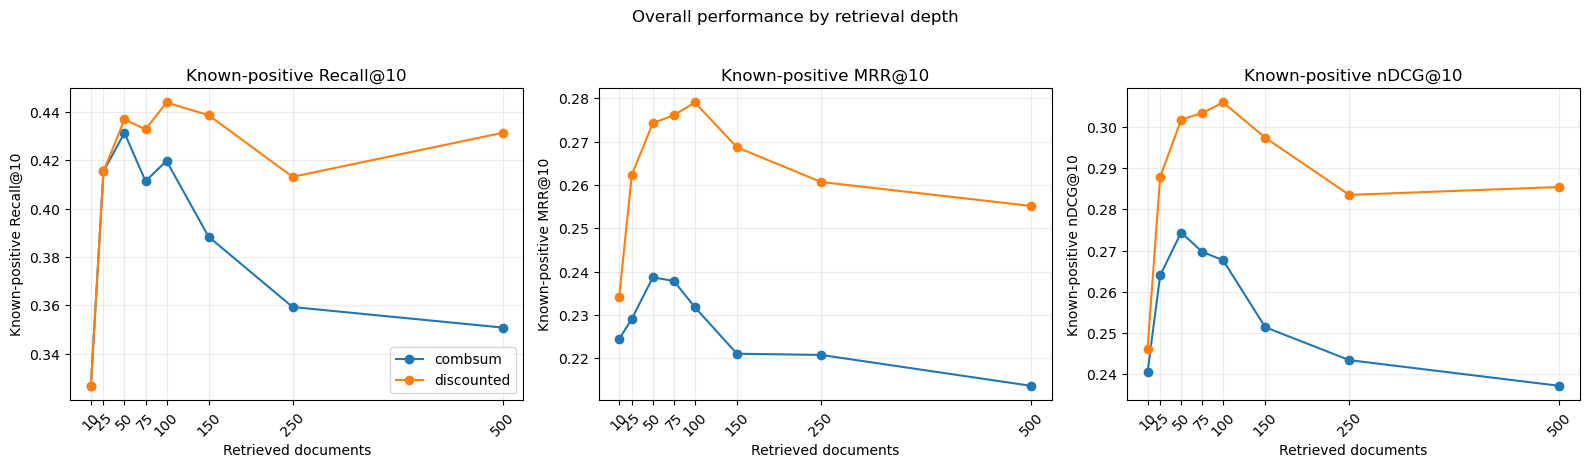

In [2]:
overall = summary[summary.query_type.eq("overall")]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, metric_labels.items()):
    for method, group in overall.groupby("method"):
        group = group.sort_values("depth")
        ax.plot(group.depth, group[col], marker="o", label=method)
    ax.set(xlabel="Retrieved documents", ylabel=label, title=label)
    ax.set_xticks(depths)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=.25)
axes[0].legend()
fig.suptitle("Overall performance by retrieval depth", y=1.03)
fig.tight_layout()
fig.savefig(OUT / "01_overall_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

## 2. Academic vs student-style queries

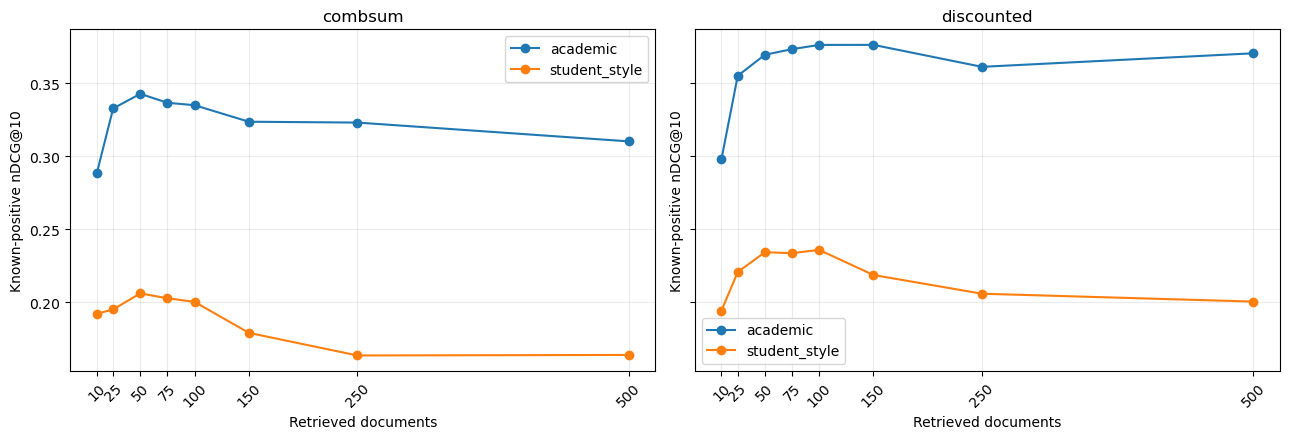

In [3]:
subset = summary[summary.query_type.ne("overall")]
fig, axes = plt.subplots(1, len(methods), figsize=(13, 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, method in zip(axes, methods):
    for qtype, group in subset[subset.method.eq(method)].groupby("query_type"):
        group = group.sort_values("depth")
        ax.plot(group.depth, group.known_ndcg_at_k, marker="o", label=qtype)
    ax.set(title=method, xlabel="Retrieved documents", ylabel="Known-positive nDCG@10")
    ax.set_xticks(depths)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=.25)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "02_query_types.png", dpi=180)
plt.show()

## 3. nDCG heatmap — all configurations

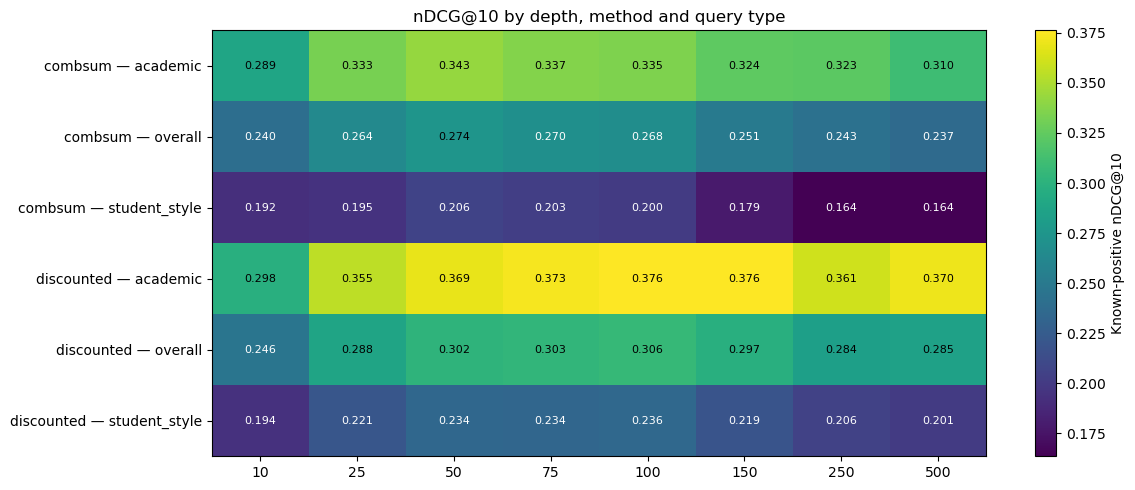

In [4]:
pivot = summary.pivot_table(index=["method","query_type"], columns="depth", values="known_ndcg_at_k")
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(pivot.to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), [f"{m} — {q}" for m,q in pivot.index])
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        value = pivot.iloc[i,j]
        ax.text(j,i,f"{value:.3f}",ha="center",va="center",color="white" if value < (pivot.values.min()+pivot.values.max())/2 else "black",fontsize=8)
fig.colorbar(im, ax=ax, label="Known-positive nDCG@10")
ax.set_title("nDCG@10 by depth, method and query type")
fig.tight_layout()
fig.savefig(OUT / "03_heatmap.png",dpi=180)
plt.show()

## 4. Candidate researcher count

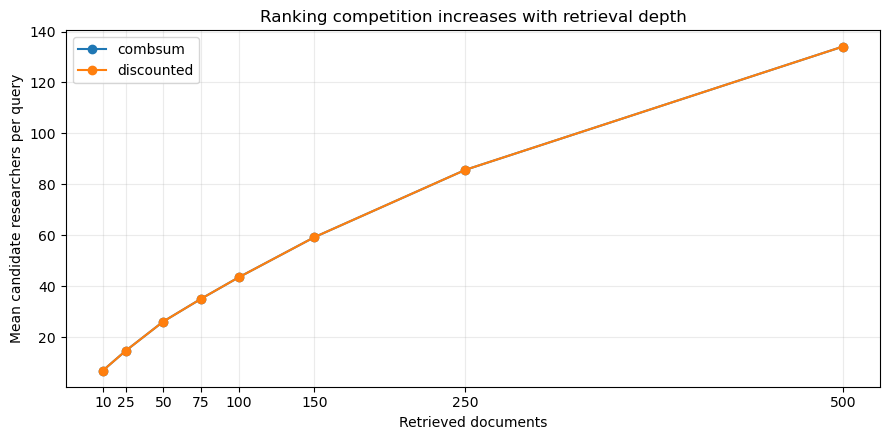

In [5]:
fig, ax = plt.subplots(figsize=(9,4.5))
for method, group in overall.groupby("method"):
    group = group.sort_values("depth")
    ax.plot(group.depth, group.candidate_researcher_count, marker="o", label=method)
ax.set(xlabel="Retrieved documents", ylabel="Mean candidate researchers per query", title="Ranking competition increases with retrieval depth")
ax.set_xticks(depths)
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "04_candidates.png",dpi=180)
plt.show()

## 5. Expected-expert status by depth
`not_retrieved` means the expert was not represented among retrieved documents; it does **not** prove the researcher lacks indexed documents.

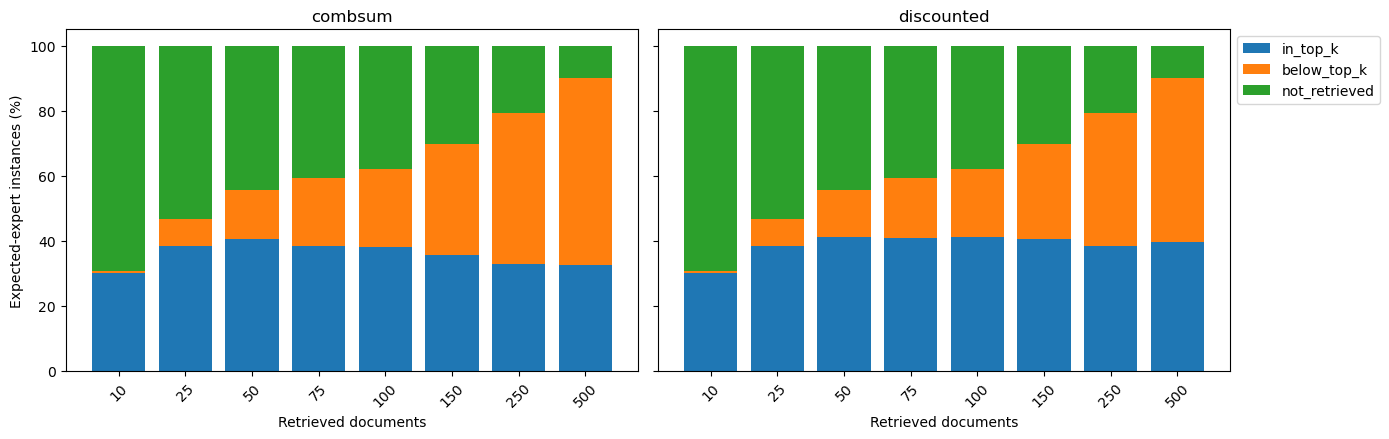

In [6]:
status_counts = (coverage.groupby(["method","depth","status"]).size()
                 .rename("n").reset_index())
status_pct = status_counts.pivot_table(index=["method","depth"],columns="status",values="n",fill_value=0)
status_pct = status_pct.div(status_pct.sum(axis=1),axis=0)*100
fig, axes = plt.subplots(1,len(methods),figsize=(14,4.5),sharey=True)
axes = np.atleast_1d(axes)
for ax, method in zip(axes, methods):
    block = status_pct.loc[method].reindex(depths)
    bottom = np.zeros(len(block))
    for status in ["in_top_k","below_top_k","not_retrieved"]:
        if status not in block: continue
        values = block[status].to_numpy()
        ax.bar(range(len(depths)),values,bottom=bottom,label=status)
        bottom += values
    ax.set_xticks(range(len(depths)),depths)
    ax.set(xlabel="Retrieved documents",title=method)
    ax.tick_params(axis="x",rotation=45)
axes[0].set_ylabel("Expected-expert instances (%)")
axes[-1].legend(loc="upper left",bbox_to_anchor=(1,1))
fig.tight_layout()
fig.savefig(OUT / "05_expert_status.png",dpi=180,bbox_inches="tight")
plt.show()

## 6. Per-query nDCG change vs depth 100
Compare the best depth for each aggregation method against the existing depth-100 setting. Differences are paired by `query_id`.

,method,depth,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k
7,combsum,50,0.431232,0.238696,0.274396
37,discounted,100,0.443768,0.279016,0.306037


combsum chosen depth 50 improved 95 unchanged 297 worsened 60
discounted chosen depth 100 improved 0 unchanged 452 worsened 0


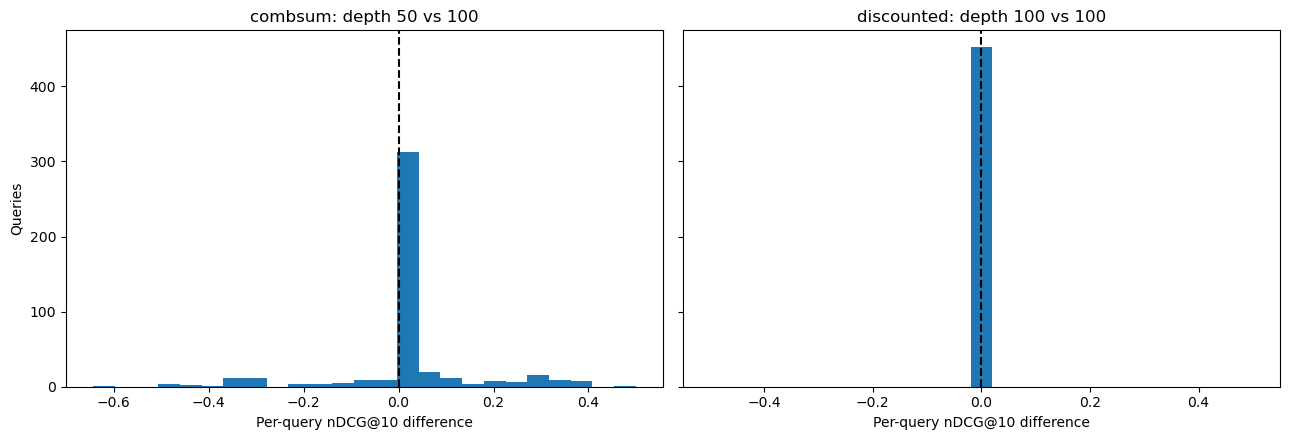

In [7]:
best = (overall.sort_values(["method","known_ndcg_at_k","depth"],ascending=[True,False,True])
        .groupby("method").head(1))
display(best[["method","depth",*metric_labels.keys()]])
fig,axes=plt.subplots(1,len(methods),figsize=(13,4.5),sharey=True)
axes=np.atleast_1d(axes)
for ax,method in zip(axes,methods):
    chosen=int(best.loc[best.method.eq(method),"depth"].iloc[0])
    part=metrics[metrics.method.eq(method)]
    wide=part.pivot(index="query_id",columns="depth",values="known_ndcg_at_k")
    diff=(wide[chosen]-wide[100]).dropna()
    ax.hist(diff,bins=25)
    ax.axvline(0,color="black",linestyle="--")
    ax.set(title=f"{method}: depth {chosen} vs 100",xlabel="Per-query nDCG@10 difference")
    print(method, "chosen depth",chosen,"improved",(diff>0).sum(),"unchanged",(diff==0).sum(),"worsened",(diff<0).sum())
axes[0].set_ylabel("Queries")
fig.tight_layout()
fig.savefig(OUT / "06_query_differences.png",dpi=180)
plt.show()

## Selection and interpretation
The grid search identifies a **development-set** preference, not a confirmed optimal cutoff. Compare the leading depths on Recall@10, MRR@10 and academic/student-style queries, and prefer the smaller depth when performance is essentially tied. A held-out test set is needed for an unbiased final estimate. Query pairs from the same source article should stay in the same split.

In [8]:
print("Best depth by mean known-positive nDCG@10 (exploratory):")
display(best[["method","depth","known_recall_at_k","known_mrr_at_k","known_ndcg_at_k"]].sort_values("method"))
print("Plots saved to:",OUT.resolve())

Best depth by mean known-positive nDCG@10 (exploratory):


,method,depth,known_recall_at_k,known_mrr_at_k,known_ndcg_at_k
7,combsum,50,0.431232,0.238696,0.274396
37,discounted,100,0.443768,0.279016,0.306037


Plots saved to: /Users/izahetmanowska/Desktop/ExpertsSearchEngine/testing/bm25_depth_results/plots


Grid search was performed across eight retrieval depths (10–500 documents) using both Standard and Discounted CombSUM. The results show that the optimal retrieval depth depends on the aggregation method. Standard CombSUM achieved its highest nDCG@10 at 50 documents (0.2744), while Discounted CombSUM performed best at 100 documents (0.3060). Increasing the retrieval depth beyond 100 generally reduced ranking effectiveness, suggesting that additional lower-ranked documents introduce noise or accumulate scores for less relevant researchers. Based on these findings, I decided to retain a cutoff of 100 documents with Discounted CombSUM for subsequent experiments. However, the differences between 50, 75, and 100 documents were relatively small, so the choice should be validated on held-out queries.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATA_DIR = Path("bm25_depth_results")
metrics = pd.read_csv(DATA_DIR / "metrics.csv")

df = metrics[
    (metrics["method"] == "discounted")
    & (metrics["depth"].isin([50, 75, 100]))
].copy()

scores = df.pivot(
    index="query_id",
    columns="depth",
    values="known_ndcg_at_k"
)[[50, 75, 100]].dropna()

print(f"Paired queries: {len(scores)}")
display(scores.head())

Paired queries: 452


depth,50,75,100
query_id,,,
1,0.000000,0.000000,0.000000
2,0.237198,0.264068,0.237198
3,0.296082,0.296082,0.296082
4,0.234639,0.296082,0.296082
5,0.630930,0.630930,0.630930


In [10]:
rng = np.random.default_rng(42)

N_BOOTSTRAP = 10_000

comparisons = [
    (100, 50),
    (100, 75),
    (75, 50),
]

results = []
bootstrap_distributions = {}

for depth_a, depth_b in comparisons:
    differences = (
        scores[depth_a] - scores[depth_b]
    ).to_numpy()

    observed = differences.mean()

    boot_means = np.empty(N_BOOTSTRAP)

    for i in range(N_BOOTSTRAP):
        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )
        boot_means[i] = sample.mean()

    ci_low, ci_high = np.percentile(
        boot_means, [2.5, 97.5]
    )

    bootstrap_distributions[f"{depth_a} vs {depth_b}"] = boot_means

    results.append({
        "comparison": f"{depth_a} vs {depth_b}",
        "mean_difference": observed,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "ci_excludes_zero": ci_low > 0 or ci_high < 0,
        "bootstrap_p_positive": (boot_means > 0).mean(),
    })

bootstrap_results = pd.DataFrame(results)

display(bootstrap_results.round(5))

,comparison,mean_difference,ci_low,ci_high,ci_excludes_zero,bootstrap_p_positive
0,100 vs 50,0.00417,-0.00836,0.01664,False,0.7392
1,100 vs 75,0.00256,-0.00701,0.01213,False,0.6959
2,75 vs 50,0.00160,-0.00843,0.01181,False,0.6189


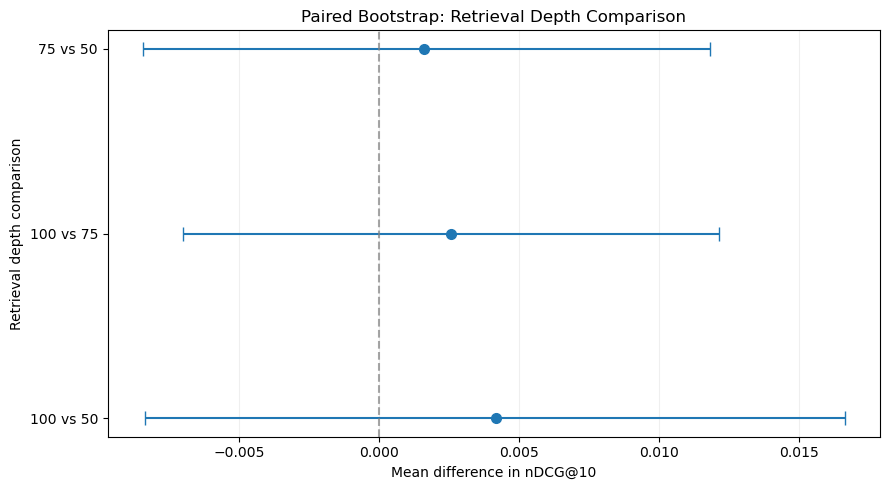

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))

y = np.arange(len(bootstrap_results))

means = bootstrap_results["mean_difference"].to_numpy()
lower = means - bootstrap_results["ci_low"].to_numpy()
upper = bootstrap_results["ci_high"].to_numpy() - means

ax.errorbar(
    means,
    y,
    xerr=[lower, upper],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.axvline(0, linestyle="--", color="gray", alpha=0.7)

ax.set_yticks(y)
ax.set_yticklabels(bootstrap_results["comparison"])

ax.set_xlabel("Mean difference in nDCG@10")
ax.set_ylabel("Retrieval depth comparison")
ax.set_title("Paired Bootstrap: Retrieval Depth Comparison")

ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

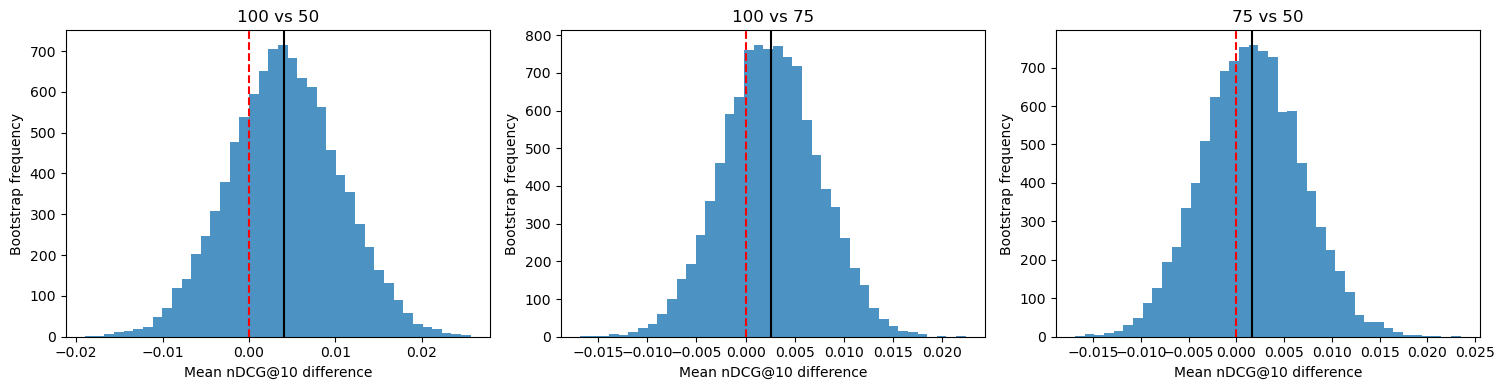

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (comparison, values) in zip(
    axes, bootstrap_distributions.items()
):
    ax.hist(values, bins=40, alpha=0.8)

    ax.axvline(0, color="red", linestyle="--")
    ax.axvline(values.mean(), color="black", linestyle="-")

    ax.set_title(comparison)
    ax.set_xlabel("Mean nDCG@10 difference")
    ax.set_ylabel("Bootstrap frequency")

plt.tight_layout()
plt.show()

I compared retrieval depths of 50, 75 and 100 documents using paired bootstrap resampling (10,000 iterations) to investigate whether the differences in nDCG@10 were meaningful.

Although 100 documents achieved the highest average nDCG@10, none of the pairwise comparisons showed a clear difference, as all 95% confidence intervals included zero. This suggests that performance is relatively stable between 50 and 100 retrieved documents.

I decided to keep the cutoff at 100 for subsequent experiments, as it achieved the highest observed performance with Discounted CombSUM and allows me to maintain consistency with the previous experiments. However, I cannot conclude that 100 is statistically superior to the smaller cutoffs.